# Financial mathematics verification (PRD section 7)

The project's own implementations in `src/northgate/finance.py` and the manual gradient-descent regression in `src/northgate/models/gradient_descent.py` are checked against independent library calculations on real data from the **training period only** (2016–2023). A difference at floating-point precision (around 1e-12 or smaller) means the hand-written formula is correct.

In [1]:
import os, sys, warnings
os.environ.setdefault("OMP_NUM_THREADS", "1")
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
pd.set_option("display.width", 160); pd.set_option("display.precision", 4)
PAL = ["#2B6CB0", "#C2571A", "#7B4FA6", "#2F8F6B"]; INK, GRID, PAPER = "#1C1B19", "#E4DFD5", "#FAF8F4"
plt.rcParams.update({"figure.facecolor": PAPER, "axes.facecolor": PAPER, "axes.edgecolor": "#8C867A", "axes.grid": True,
                     "grid.color": GRID, "axes.spines.top": False, "axes.spines.right": False, "font.size": 9,
                     "axes.titlesize": 10, "figure.dpi": 90, "axes.prop_cycle": plt.cycler(color=PAL)})
TRAIN_END = pd.Timestamp("2023-12-29")   # last feature date of the training partition
panel = pd.read_csv(ROOT / "data/processed/market_panel.csv", parse_dates=["Date"])
panel = panel[panel.Date <= TRAIN_END]   # validation and test periods are excluded
px = panel.pivot(index="Date", columns="Ticker", values="Adj Close")
vol = panel.pivot(index="Date", columns="Ticker", values="Volume")
r = np.log(px).diff().iloc[1:]
EQ = [c for c in px.columns if c != "^NSEI"]
short = lambda t: t.replace(".NS", "").replace("^NSEI", "NIFTY 50")
print(f"Training period: {px.index.min():%d %b %Y} to {px.index.max():%d %b %Y}; {len(px)} sessions; {len(EQ)} stocks + NIFTY 50")

Training period: 01 Jan 2016 to 29 Dec 2023; 1975 sessions; 10 stocks + NIFTY 50


## 1. Returns, risk and portfolio measures: scratch versus library

In [2]:
from northgate import finance as FN
pxs = px[EQ]; sr = pxs.pct_change().iloc[1:]; m = px["^NSEI"].pct_change().iloc[1:]; s = sr["RELIANCE.NS"]; rf = 0.065
w = pd.Series(1 / len(EQ), index=EQ); port = (sr * w).sum(axis=1)
def mdd_alt(x):
    v = np.cumprod(1 + x.values); return float((v / np.maximum.accumulate(v) - 1).min())
ex = s - rf / 252
rows = [
 ("Simple returns (max abs diff)", float((FN.simple_returns(pxs).iloc[1:] - pxs.pct_change().iloc[1:]).abs().max().max()), 0.0),
 ("Log returns (max abs diff)", float((FN.log_returns(pxs).iloc[1:] - np.log1p(pxs.pct_change().iloc[1:])).abs().max().max()), 0.0),
 ("Annualised mean return, RELIANCE", FN.annualise_mean(s), float(np.mean(s) * 252)),
 ("Annualised volatility, RELIANCE", FN.annualise_vol(s), float(np.std(s, ddof=1) * np.sqrt(252))),
 ("Covariance matrix (max abs diff)", float(np.abs(FN.covariance(sr).to_numpy() - np.cov(sr.to_numpy().T, ddof=1)).max()), 0.0),
 ("Correlation from covariance, RELIANCE-HDFCBANK", float(FN.covariance(sr).loc["RELIANCE.NS", "HDFCBANK.NS"] / (sr["RELIANCE.NS"].std() * sr["HDFCBANK.NS"].std())), float(sr["RELIANCE.NS"].corr(sr["HDFCBANK.NS"]))),
 ("Beta, RELIANCE vs NIFTY 50 (common dates)", FN.beta(s, m), float(np.polyfit(*pd.concat([m, s], axis=1).dropna().to_numpy().T, 1)[0])),
 ("Sharpe ratio, RELIANCE (rf 6.5%)", FN.sharpe(s, rf), float(ex.mean() / ex.std() * np.sqrt(252))),
 ("Sortino ratio, RELIANCE", FN.sortino(s, rf), float(ex.mean() / np.sqrt(np.mean(np.minimum(ex, 0) ** 2)) * np.sqrt(252))),
 ("Maximum drawdown, RELIANCE", FN.max_drawdown(s), mdd_alt(s)),
 ("Historical VaR 95%, RELIANCE", FN.var_historical(s), float(np.percentile(s, 5))),
 ("Calmar ratio, RELIANCE", FN.calmar(s), float(((1 + s).prod() ** (252 / len(s)) - 1) / abs(mdd_alt(s)))),
 ("Portfolio variance w'Σw vs variance of portfolio returns", float(w @ FN.covariance(sr) @ w), float(np.var(port, ddof=1))),
]
check = pd.DataFrame(rows, columns=["Quantity", "Northgate (scratch)", "Library / independent"])
check["Absolute difference"] = (check.iloc[:, 1] - check.iloc[:, 2]).abs()
display(check.style.format({"Northgate (scratch)": "{:.10f}", "Library / independent": "{:.10f}", "Absolute difference": "{:.2e}"}))
print("Largest absolute difference:", f"{check['Absolute difference'].max():.2e}")

,Quantity,Northgate (scratch),Library / independent,Absolute difference
0,Simple returns (max abs diff),0.0000000000,0.0000000000,0.00e+00
1,Log returns (max abs diff),0.0000000000,0.0000000000,0.00e+00
2,"Annualised mean return, RELIANCE",0.2651342025,0.2651342025,0.00e+00
3,"Annualised volatility, RELIANCE",0.2832790523,0.2832790523,0.00e+00
4,Covariance matrix (max abs diff),0.0000000000,0.0000000000,0.00e+00
5,"Correlation from covariance, RELIANCE-HDFCBANK",0.3889749879,0.3889749879,8.88e-16
6,"Beta, RELIANCE vs NIFTY 50 (common dates)",1.0765562155,1.0765562155,2.22e-16
7,"Sharpe ratio, RELIANCE (rf 6.5%)",0.7064913586,0.7064913586,0.00e+00
8,"Sortino ratio, RELIANCE",1.0688577983,1.0688577983,0.00e+00
9,"Maximum drawdown, RELIANCE",-0.4508835692,-0.4508835692,0.00e+00


Largest absolute difference: 8.88e-16


**Result.** Every hand-written quantity matches its independent counterpart to floating-point precision. The definitions used throughout the dashboard are: simple return (P_t − P_{t−1})/P_{t−1}; log return ln(P_t/P_{t−1}); annualisation ×252 for means and ×√252 for volatility; Sharpe (μ − r_f)/σ; Sortino with downside deviation; maximum drawdown min(V_t / max V − 1); historical VaR as the 5th percentile; Calmar as CAGR / |maximum drawdown|; portfolio variance wᵀΣw.

## 2. Optimisation check: manual gradient descent versus closed-form OLS

,gradient descent,closed-form OLS,scikit-learn,|GD - OLS|
intercept,8.949e-04,8.949e-04,8.949e-04,2.168e-19
return_1d,-3.823e-04,-3.823e-04,-3.823e-04,5.421e-20
return_5d,-4.172e-05,-4.172e-05,-4.172e-05,4.743e-19
price_sma_ratio_20,-2.408e-04,-2.408e-04,-2.408e-04,1.924e-18
volatility_20d,1.118e-03,1.118e-03,1.118e-03,8.674e-19
rsi_14,6.240e-04,6.240e-04,6.240e-04,1.518e-18


Converged in 20000 epochs; max |GD - OLS| = 1.92e-18; training R² = 0.0042 on 1954 rows


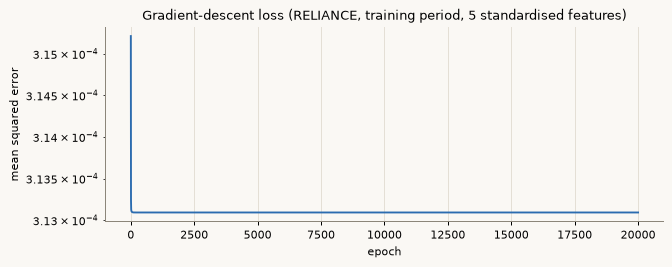

In [3]:
from northgate import features as F
from northgate.models.gradient_descent import gd_linreg, ols_closed_form
from sklearn.linear_model import LinearRegression
feat = F.partition(F.add_labels(F.build(pd.read_csv(ROOT / "data/processed/market_panel.csv", parse_dates=["Date"]))), "train")
d = feat[feat.Ticker == "RELIANCE.NS"].dropna(subset=[F.TARGET])
cols = ["return_1d", "return_5d", "price_sma_ratio_20", "volatility_20d", "rsi_14"]
d = d.replace([np.inf, -np.inf], np.nan).dropna(subset=cols); X = d[cols].to_numpy(); X = (X - X.mean(0)) / X.std(0); y = d[F.TARGET].to_numpy()
w_gd, b_gd, hist = gd_linreg(X, y, lr=0.1, epochs=20000, tol=0.0)
w_ols, b_ols = ols_closed_form(X, y); sk = LinearRegression().fit(X, y)
coef = pd.DataFrame({"gradient descent": np.r_[b_gd, w_gd], "closed-form OLS": np.r_[b_ols, w_ols], "scikit-learn": np.r_[sk.intercept_, sk.coef_]},
                    index=["intercept"] + cols)
coef["|GD - OLS|"] = (coef["gradient descent"] - coef["closed-form OLS"]).abs()
display(coef.style.format("{:.3e}"))
print(f"Converged in {len(hist)} epochs; max |GD - OLS| = {coef['|GD - OLS|'].max():.2e}; training R² = {sk.score(X, y):.4f} on {len(y)} rows")
fig, ax = plt.subplots(figsize=(8, 2.8)); ax.plot(hist, color=PAL[0]); ax.set_yscale("log"); ax.set_xlabel("epoch"); ax.set_ylabel("mean squared error")
ax.set_title("Gradient-descent loss (RELIANCE, training period, 5 standardised features)"); plt.show()

**Result.** Gradient descent converges to the same coefficients as the normal-equation solution and scikit-learn (the largest difference is printed above), confirming the update rule θ ← θ − η∇L. The fitted regression explains almost none of the variance in next-session returns (training R² near zero), which agrees with the EDA finding of negligible return autocorrelation and with the validation result that no model beat the naive forecast.